# Task 4 – Facial Recognition Model (Training)

**Owner:** Shema
**Reads:** `data/cleaned_data/image_features.csv`
**Writes:** `models/face_model.joblib`

**Goal:** given a photo, say **which team member** it belongs to, *or* say **"unknown"** if it doesn't clearly match anyone. The second part is what makes the **unauthorized attempt** fail.

**Scores we track** (same as the product model, so all three models are compared the same way):
- **Accuracy:** the share of correct guesses. Guessing at random gives 33% with the 3 members currently enrolled (25% once all 4 are in).
- **F1-score (macro):** accuracy that treats every member fairly.
- **Loss (log loss):** how confident-and-wrong the model is. Lower is better. Random guessing gives 1.10 (ln 3) with 3 members, or 1.39 (ln 4) with 4.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))   # reuse the project code in src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config as C

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
import joblib
from sklearn.metrics import ConfusionMatrixDisplay
from identity_model import train_identity_model, save_bundle, identify, feature_columns
from image_pipeline import image_to_features

df = pd.read_csv(C.IMAGE_FEATURES_CSV)
print(df.shape)
df.iloc[:, :8].head()

(45, 363)


,member,expression,augmentation,source_image,face_detected,hog_0,hog_1,hog_2
0,peggy,neutral,original,peggy/peggy_neutral.jpg,1,0.142375,0.155935,0.122370
1,peggy,neutral,rotate_15,peggy/peggy_neutral.jpg,1,0.211674,0.212324,0.162394
2,peggy,neutral,flip,peggy/peggy_neutral.jpg,1,0.160959,0.212819,0.224876
3,peggy,neutral,grayscale,peggy/peggy_neutral.jpg,1,0.142375,0.155935,0.122370
4,peggy,neutral,brightness,peggy/peggy_neutral.jpg,1,0.149913,0.152327,0.140373


In [2]:
print("Rows per member:"); print(df.member.value_counts().to_string())
print("\nOriginal photos per member:"); print(df.groupby("member")["source_image"].nunique().to_string())
print("\nFeatures:", len(feature_columns(df)), "| missing values:", df.isna().sum().sum())

Rows per member:
member
peggy        15
santhiana    15
shema        15

Original photos per member:
member
peggy        3
santhiana    3
shema        3

Features: 358 | missing values: 0


**Result:** 15 rows per member, from 3 original photos each, with 358 features and no missing values. With 3 photos per member, cross-validation uses **3 folds**: each fold trains on 2 photos per member and tests on the third, which the model has never seen.

## 1. A fair test: split by original photo

Every photo appears 5 times in the table (the original plus its 4 augmented copies).
- **If we split rows at random**, a flipped copy could land in training while the original lands in testing. The model would effectively have seen the answer, and the score would look much better than it really is.
- **So we split by `source_image`** using `StratifiedGroupKFold`: every copy of one photo always stays on the same side, and each fold still contains every member.

This is the same idea the product model uses when it splits by customer.

The number of folds equals the smallest number of original photos any member has. Each fold therefore tests one unseen photo per member.

## 2. Compare two models and pick the best

| Model | Why we try it |
|---|---|
| **Logistic Regression** (with standard scaling) | Simple, fast, and gives well-calibrated probabilities, which matters for the confidence threshold. |
| **Random Forest** (300 trees, at least 2 rows per leaf) | Handles non-linear patterns and needs no scaling. The leaf limit stops it from memorising single rows. |

The model with the best cross-validated **F1** wins. If the F1 scores tie, the lower **loss** wins.

In [3]:
bundle = train_identity_model(df, group_col="source_image")

Rows: 45 from 9 original files | 3-fold grouped CV
              model  accuracy  f1_macro  log_loss
Logistic Regression     0.933     0.933     0.151
      Random Forest     0.867     0.861     0.489

Chosen: Logistic Regression
  CV    -> acc 0.93 | F1 0.93 | loss 0.15
  Train -> acc 1.00 | F1 1.00 | loss 0.00
  Confidence threshold: 0.66
  CV genuine attempts accepted: 76% | accepted as the WRONG member: 0%


**Result:** **Logistic Regression wins** (accuracy 0.93, F1 0.93, loss 0.15) over the Random Forest (0.87, 0.86, 0.49). With 358 features and only 45 rows, a linear model with scaled features generalises better than a forest, which tends to memorise individual photos. Its probabilities are also better calibrated (lower loss), and the confidence threshold depends on that.

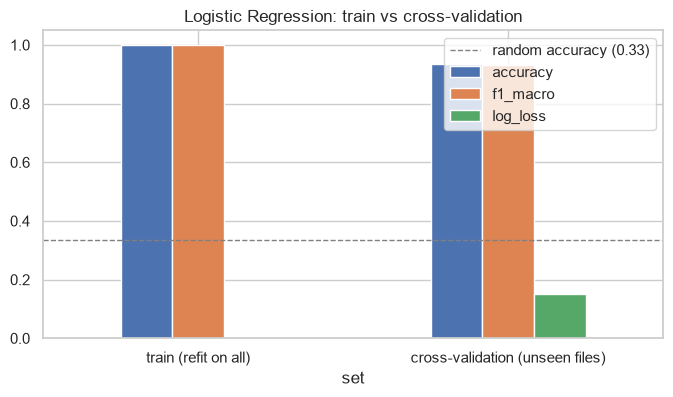

,accuracy,f1_macro,log_loss
set,,,
train (refit on all),1.000,1.000,0.002
cross-validation (unseen files),0.933,0.933,0.151


In [4]:
b = bundle
summary = pd.DataFrame([{"set": "train (refit on all)", **b["train_scores"]},
                        {"set": "cross-validation (unseen files)", **b["cv_scores"]}]).set_index("set")
ax = summary.plot(kind="bar", figsize=(8, 4), rot=0)
chance = 1 / len(b["classes"])
ax.axhline(chance, color="grey", ls="--", lw=1, label=f"random accuracy ({chance:.2f})")
ax.set_title(f"{b['model_name']}: train vs cross-validation"); ax.legend(loc="upper right"); plt.show()
summary.round(3)

**Is it overfitting?** A little. On the training photos the model is perfect (accuracy 1.00, loss 0.00), and on unseen photos it drops to 0.93 accuracy and 0.15 loss.
- **The gap is small,** so the model genuinely recognises faces it hasn't seen.
- **The unseen photos aren't very unseen, though.** Each member's photos share a place, light and clothes, so a held-out photo is still very similar to the training ones. The real test is a new photo taken somewhere else.

**How to read it:**
- The **train** scores come from the model refit on every row, so they are optimistic.
- The **cross-validation** scores come from photos the model never saw, and these are the honest numbers.
- A big gap between the two (for example 1.00 train vs 0.70 CV) means the model memorises. A small gap means it generalises.

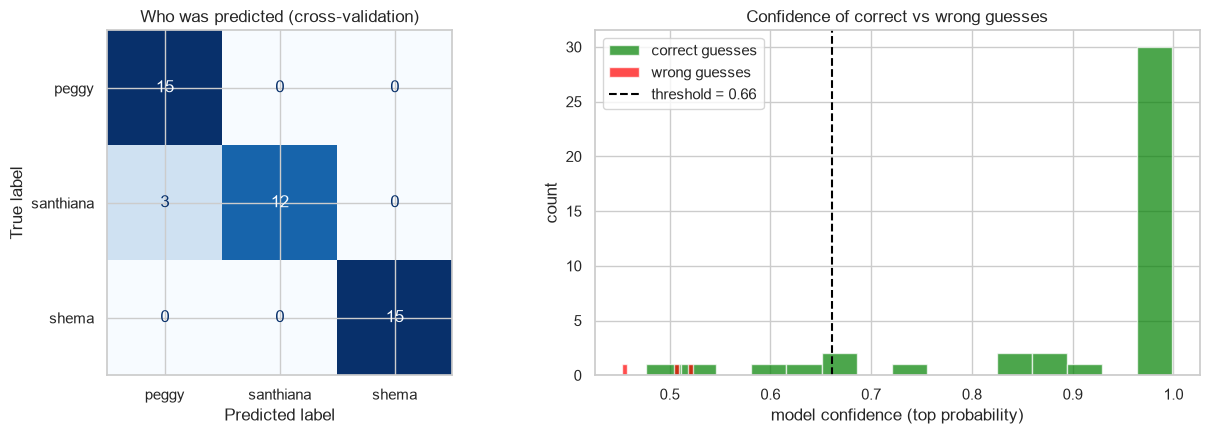

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay(b["confusion"], display_labels=sorted(df.member.unique())).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Who was predicted (cross-validation)")

conf = b["oof_proba"].max(1)
pred = np.array(sorted(df.member.unique()))[b["oof_proba"].argmax(1)]
right = pred == b["oof_true"]
axes[1].hist(conf[right], bins=15, alpha=0.7, label="correct guesses", color="green")
axes[1].hist(conf[~right], bins=15, alpha=0.7, label="wrong guesses", color="red")
axes[1].axvline(b["threshold"], color="black", ls="--", label=f"threshold = {b['threshold']:.2f}")
axes[1].set_xlabel("model confidence (top probability)"); axes[1].set_ylabel("count")
axes[1].set_title("Confidence of correct vs wrong guesses"); axes[1].legend()
plt.tight_layout(); plt.show()

**What it shows:**
- **Peggy and Shema:** recognised every time (15/15).
- **Santhiana:** 12 of 15 correct, and 3 rows mistaken for Peggy. Her photos are the most varied (three places and lights), so when one is held out, the remaining two look less like it.
- **Confidence (right):** 30 correct guesses are almost 100% confident. All the wrong guesses sit around 0.45–0.52, **below the 0.66 threshold**. They would be rejected as "unknown", never accepted as the wrong person.

## 3. Decision rule: when do we say "unknown"?

A normal classifier **always** picks one of the 4 members, even for a stranger. To be able to say *no*, the system uses two checks:

1. **Confidence threshold:** the model's top probability must be at least the threshold.
   - The threshold is set automatically to the confidence reached by **90% of correct** cross-validation guesses. In other words, we accept about 90% of genuine attempts.
   - It is kept between 0.40 and 0.85.
   - In the right-hand histogram, the wrong guesses (red) should mostly fall to the left of the dashed line, which means they get rejected.
2. **Novelty check (Local Outlier Factor):** this asks whether the input looks like *anything* in the training data. A stranger's photo sits far from every member's points, so it's flagged even if the classifier happens to be confident.

Access is granted only when both checks pass.

In [6]:
print(f"Genuine attempts accepted (cross-validation): {b['genuine_accept_rate']:.0%}")
print(f"Accepted as the WRONG member               : {b['wrong_member_accept_rate']:.0%}")
print(f"Flagged as 'unknown' by the novelty check   : {b['oof_novel'].mean():.0%} of genuine attempts")

Genuine attempts accepted (cross-validation): 76%
Accepted as the WRONG member               : 0%
Flagged as 'unknown' by the novelty check   : 9% of genuine attempts


**Result:**
- **76% of genuine attempts are accepted.** About 1 in 4 genuine logins with a new photo would need a second try. That's the price of rejecting strangers safely.
- **No attempt is accepted as the wrong member.**
- **The novelty check flags 9% of genuine attempts,** which is part of that 24%.

## 4. Unauthorized attempt: a non-member must be rejected

In [7]:
files = [p for p in sorted(C.IMG_UNAUTH_DIR.glob("*")) if p.suffix.lower() in C.IMAGE_EXTS]
if not files:
    print("No file in", C.IMG_UNAUTH_DIR, "- add a non-member sample (or run: python src/make_unauthorized_samples.py)")
for p in files:
    r = identify(b, image_to_features(p)[0])
    print(f"{p.name}: {'ACCEPTED as ' + r['member'] if r['accepted'] else 'REJECTED'}  ->  {r['reason']}")
    print("   probabilities:", r["probabilities"])

stranger_astronaut.jpg: REJECTED  ->  input does not look like any enrolled team member (novelty check)
   probabilities: {'peggy': np.float64(0.984), 'santhiana': np.float64(0.001), 'shema': np.float64(0.015)}


**Result:** the stranger is **rejected**. Notice *how*: the classifier alone was **98% sure it was Peggy**, which is far above the threshold. Only the novelty check caught it. A closed-set classifier is confidently wrong on faces it was never trained on, so the novelty check is essential.

## 5. Save the model

In [8]:
save_bundle(b, C.FACE_MODEL_PATH)
print("Saved:", C.FACE_MODEL_PATH, "| keys:", list(joblib.load(C.FACE_MODEL_PATH).keys()))

Saved: C:\Users\PeggyDusenge\Desktop\U\UserIdentityandProductRecommendationSystem\models\face_model.joblib | keys: ['model', 'novelty', 'features', 'classes', 'threshold', 'model_name', 'cv_scores', 'train_scores', 'genuine_accept_rate', 'wrong_member_accept_rate']


## Summary
- **Validation:** grouped by original photo, so augmented copies never leak into the test fold.
- **Model choice:** Logistic Regression (CV accuracy 0.93, F1 0.93, loss 0.15) beat Random Forest (0.87, 0.86, 0.49).
- **Errors:** the only mistakes were 3 of Santhiana's rows, all below the threshold, so they're rejected rather than misidentified.
- **Stranger:** the classifier was 98% sure the stranger was Peggy; the novelty check rejected it.
- **Overfitting:** mild (train loss 0.00 vs CV 0.15). Photos from new places and lighting would test it properly.
- **Metrics reported:** accuracy, F1, loss (train vs CV) and a confusion matrix.
- **Rejecting strangers:** the confidence threshold plus the novelty check let the model answer *"unknown"*, which the command-line app uses to deny access.
- **Saved to:** `models/face_model.joblib`, which `app/cli.py` loads.

The same steps can be run without Jupyter: `python src/train_face_model.py --rebuild`.